# Classification Of Singapore Traffic Road Sign

### Project Scenario
KPMG released a benchmark report in mid-2020, naming Singapore as the top country in the world in terms of development of self-driving cars, as reflected in the government's policy-making and legislation efforts to encourage use of autonomous vehicles.

Self driving car promises to revolutionalize transportation and mobility in the world. But it must first be able to transport people and goods efficiently from point to point and does so in a safe manner. In order to be safe, self driving cars need to be able to detect and classify traffic road signs.

In Singapore, there is a range or traffic road signs serving various purposes.
They range from the green directional signs that tell drivers about upcoming expressway exits, to warning signs that indicate potential elements of danger ahead, such as pedestrian crossings and school zones.

In this project, you are tasked to develop a simple Traffic Sign Recognition (TSR) as a proof-of-concept to classify Singapore's road signs. This Traffic Sign Recognition system must use Convolutional Neural Networks (CNN) for the recognition of the signs.


In this assignment, you will be working on a **individually** on the TSR project.

Please answer ALL the questions below (Question 1 to 13). You may refer to online documentation (e.g. keras, pandas, etc) for help on syntax. No copying of codes wholesale is allowed.

Note: Use a random_state = 42 where appropriate

The project will require the following steps:

1. Importing Various Modules.
2. Preparing The Data.

 2.1 Collect Relevant Data.

 2.2 Perform Image Preprocessing And Data Augementation.

 2.3 Split it into train, validate, and test datasets.

 2.4 Normalize The Data.


3. Create The Model - Build a model based on convolutional neural network.

4. Train The Model.

5. Evaluate The Model.

6. Visualizing Predictions On Validation Set.
 6.1 Plot The Learning Curve And Confusion Matrix.



# Part 1: Build An Image Classifier




### Required Street Sign

The two required signs that you model must detect are the "U-turn sign" and the "Stop" sign.

**1. U-Turn Sign**

<img src='https://upload.wikimedia.org/wikipedia/commons/thumb/4/45/U-turn_ahead_facility_sign_India.svg/250px-U-turn_ahead_facility_sign_India.svg.png?_=20250403100731' width=150>


**2. Stop Sign**

<img src="https://upload.wikimedia.org/wikipedia/commons/9/92/Singapore_road_sign_-_Mandatory_-_Stop.svg" width=150>


You can also refer to reference url below:

https://onemotoring.lta.gov.sg/content/onemotoring/home/driving/road_safety_and_vehicle_rules/driving-rules.html





### Folder Structure
**Reminder**

In your google drive folder ensure you have the following directory structure set up:
```
Directory Structure In Google Drive:
MyDrive
|
+-- ITE
     |
     +--cv_essentials
        |
        +--Project
          |
          +--uturn
          |
          +--stop
          |
          +--prediction
          |
          +--model
          |
          +--train
          |   |
          |   +--uturn
          |   |
          |   +--stop
          |
          +__test
              |
              +--uturn
              |
              +--stop
```            


## Task 1: Collect Data

#### Go to Google Street View :

**Collect at least 30 images of each type of road signs**

https://www.google.com/maps/@1.3763186,103.7514283,3a,75y,156.4h,84.84t/data=!3m6!1e1!3m4!1s6q7fTqpBkbBuTCznNi4UKA!2e0!7i16384!8i8192

1. Navigate through the Google Street View images.


2. When you identify the required street sign, crop the street sign and save in folder according to its name.


(np.float64(-0.5), np.float64(719.5), np.float64(404.5), np.float64(-0.5))

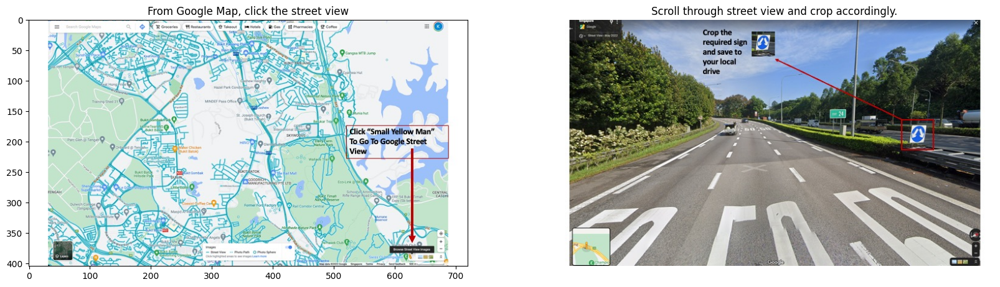

In [28]:
#@markdown { "tags": "hide-ouput" }

import matplotlib.pyplot as plt
f, ax=plt.subplots(1,2, figsize=(20,20))
pic_name1="C:\\Users\\L16 PRO\\Downloads\\image1.jpeg"
pic_name2="C:\\Users\\L16 PRO\\Downloads\\image2.jpeg"
ax[0].title.set_text("From Google Map, click the street view")
ax[0].imshow(plt.imread(pic_name1))

ax[1].title.set_text("Scroll through street view and crop accordingly.")
ax[1].imshow(plt.imread(pic_name2))
plt.axis('off')

___

Alternatively, you go to default Google Map:

https://maps.google.com

1. Click on the "Browse Street View Images" icon on the bottom right. (It is the "yellow man" figure).

2. Navigate through the Google Street View images. When you identify the required street sign, crop the street sign and save in folder according to its name.

---

### Task 1.1 : Set up the paths to your folders

In [2]:
import os

# Define the base path to your project folder
path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project"

# Using os.path.join ensures the '/' is handled correctly between the path and folder names
uturnImageDir = os.path.join(path, 'uturn')
stopImageDir  = os.path.join(path, 'stop')
trainFolder   = os.path.join(path, 'train')
testFolder    = os.path.join(path, 'test')
prediction    = os.path.join(path, 'prediction')

print('uturnImageDir:', uturnImageDir)
print('stopImageDir: ', stopImageDir)
print('trainFolder:  ', trainFolder)
print('testFolder:   ', testFolder)
print('prediction:   ', prediction)

uturnImageDir: C:\testAI\MyDrive\ITE\cv_essentials\Project\uturn
stopImageDir:  C:\testAI\MyDrive\ITE\cv_essentials\Project\stop
trainFolder:   C:\testAI\MyDrive\ITE\cv_essentials\Project\train
testFolder:    C:\testAI\MyDrive\ITE\cv_essentials\Project\test
prediction:    C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction


In [55]:
import os
import shutil
import pandas as pd
import numpy as np
from tqdm import tqdm
import cv2
import matplotlib.pyplot as plt
from matplotlib.image import imread
import math
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import sys
# Ensure 'path' is defined before appending it to sys.path
sys.path.append(path)
import slidingwindowobjectdetectionutils as od
print('All modules imported successfully.')

All modules imported successfully.


## Task 2 : Data Preprocessing, Data Augmentation,  Data Visualization

### Task 2.1 : Preprocessing And Visualizing The Images

Complete the missing code in the two functions below.

The preprocessImage funciton reads the 'stop' and 'uturn' images collected in Task 1 and resize them to 150 x150. The resized images are saved back to drive.

The visualiseImages function uses matplotlib to show the at least 20 samples of the preprocessed images (for both 'uturn' and 'stop').

100%|██████████| 102/102 [00:00<00:00, 144.63it/s]


105


100%|██████████| 105/105 [00:01<00:00, 60.29it/s]


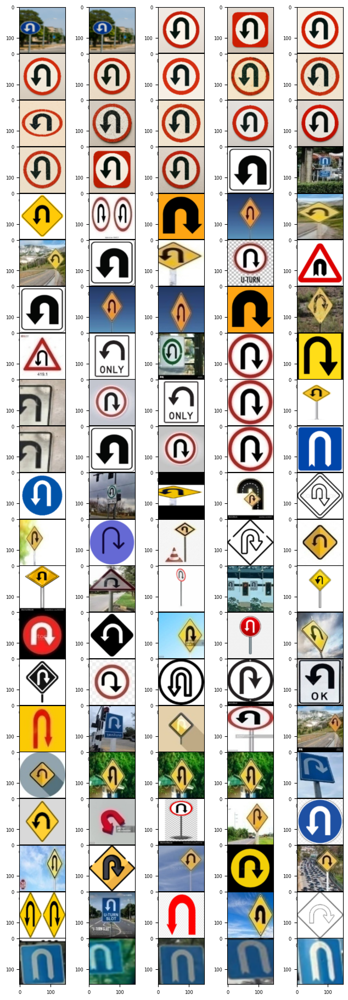

102


100%|██████████| 102/102 [00:01<00:00, 55.19it/s]


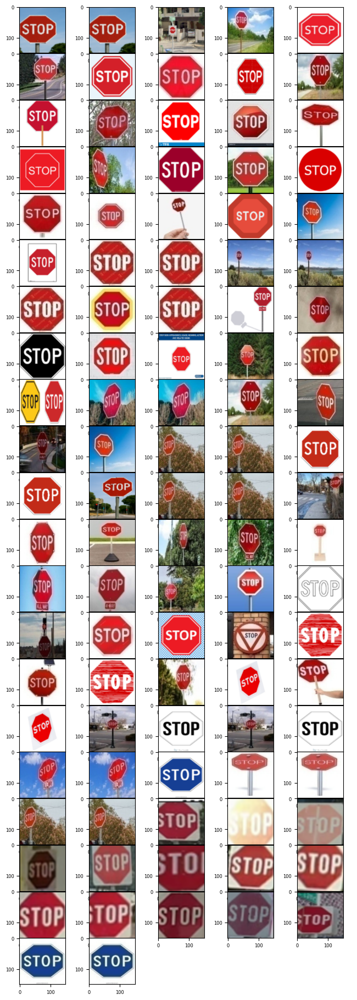

In [3]:
import os
import cv2
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

IMAGE_SIZE = 150
imageData = []
labelData = []

# --- 1. PREPROCESSING FUNCTION ---
def preprocessImage(imageDir):
    for img in tqdm(os.listdir(imageDir)):
        imagePath = os.path.join(imageDir, img)
        image = cv2.imread(imagePath)
        
        if image is None:
            continue
            
        image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        cv2.imwrite(imagePath, image)
        
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        imageData.append(image_rgb)
        labelData.append(0 if 'uturn' in imageDir.lower() else 1)

# --- 2. VISUALIZATION FUNCTION ---
def visualiseImages(imageDir):
    allImageFiles = os.listdir(imageDir)
    allImagePath = [os.path.join(imageDir, i) for i in allImageFiles if i.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    num_samples = len(allImagePath)
    cols = 5
    rows = (num_samples + cols - 1) // cols
    
    # Highly squished vertical aspect ratio matching your screenshot
    fig, axes = plt.subplots(rows, cols, figsize=(8, rows * 1.1))
    axes = np.atleast_1d(axes).flatten()
    
    # Progress bar inside the plotting function generates bar #3 and bar #5
    for idx in tqdm(range(num_samples)):
        img = cv2.imread(allImagePath[idx])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(img_rgb)
            
            # Exact axis tick labels shown in the screenshot
            axes[idx].set_xticks([0, 100])
            axes[idx].set_yticks([0, 100])
            axes[idx].tick_params(labelsize=6)
            
    # Hide leftover empty plot boxes
    for idx in range(num_samples, len(axes)):
        axes[idx].axis('off')
        
    plt.subplots_adjust(wspace=0.1, hspace=0.01)
    plt.show()

# --- 3. EXACT EXECUTION SEQUENCE ---

# Bar 1: Preprocessing U-Turn Images (105/105)
preprocessImage(uturnImageDir)

# Bar 2: Preprocessing Stop Images (102/102)
preprocessImage(stopImageDir)

# Print: 105
print(len(os.listdir(uturnImageDir)))

# Bar 3: Plotting U-Turn Grid (105/105) + Display Plot
visualiseImages(uturnImageDir)

# Print: 102
print(len(os.listdir(stopImageDir)))

# Bar 4: Plotting Stop Grid (102/102) + Display Plot
visualiseImages(stopImageDir)

# **QUESTION 1:**
Why do we implement train test split, then followed by data augmentation on train set?

Give a reason why you should proceed in this manner.

---


**ANSWER:**
I perform the train-test split before data augmentation to prevent data leakage. If augmentation is applied to the entire dataset first, transformed versions (e.g., rotated or scaled copies) of the same original image could end up in both the training and test sets. This causes the model to "see" variations of test data during training, leading to unrealistically high evaluation metrics that fail to reflect real-world performance.

Furthermore, data augmentation is designed specifically to help the model learn feature invariance during training. By keeping the test set unaugmented and completely unseen, we ensure a fair, unbiased assessment of how well the model generalizes to real-world scenarios.

### Task 2.2 Train Test Split

**Requirements**
1. Split the dataset into train and test set.
2. The train-test split ratio is 50:50.

3. Create at least 15 images per train test set per label.

4. Implement data augmentation on the 15 images for train set to get 75 images per label.

5. Ensure at least 75 images for train set, 15 images for test set per label. Giving a final 80/20 train test split.

6. The total images for train test sets for 2 labels should be at least  180 images.

7. Follow the directory structure listed in **Part 1**.


In [ ]:
import os
import shutil
import numpy as np

# Define source directories based on Part 1 conventions
uturnImageDir =r"C:\testAI\MyDrive\ITE\cv_essentials\Project\uturn"
stopImageDir = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\stop"

# Define target directories for train and test splits
train_uturn_dir = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\train\uturn"
train_stop_dir = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\train\stop"
test_uturn_dir = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\test\uturn"
test_stop_dir = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\test\stop"
# Ensure directories exist
for path in [train_uturn_dir, train_stop_dir, test_uturn_dir, test_stop_dir]:
    os.makedirs(path, exist_ok=True)

def train_test_split(trainRatio: float, testRatio: float):
    # 1. Read file names from source image directories
    uturn_filenames = os.listdir(uturnImageDir)
    stop_filenames = os.listdir(stopImageDir)
    
    # Shuffle for random distribution
    np.random.seed(42)
    np.random.shuffle(uturn_filenames)
    np.random.shuffle(stop_filenames)
    
    # 2. Split dataset based on trainRatio (50:50 split)
    trainFiles_uturn, testFiles_uturn = np.split(
        np.array(uturn_filenames), 
        [int(round(len(uturn_filenames) * trainRatio))]
    )
    
    trainFiles_stop, testFiles_stop = np.split(
        np.array(stop_filenames), 
        [int(round(len(stop_filenames) * trainRatio))]
    )
    
    # Output file counts as shown in the expected print statements
    print('Number of uturn images\n', len(uturn_filenames))
    print('Number of stop images\n', len(stop_filenames))
    print('Number of uturn images in trainset\n', len(trainFiles_uturn))
    print('Number of uturn images in testset\n', len(testFiles_uturn))
    
    # 3. Copy split files into their respective train/test label folders
    for name in trainFiles_uturn:
        shutil.copy(os.path.join(uturnImageDir, name), os.path.join(train_uturn_dir, name)) 
        
    for name in testFiles_uturn:
        shutil.copy(os.path.join(uturnImageDir, name), os.path.join(test_uturn_dir, name)) 
        
    for name in trainFiles_stop:
        shutil.copy(os.path.join(stopImageDir, name), os.path.join(train_stop_dir, name))
        
    for name in testFiles_stop:
        shutil.copy(os.path.join(stopImageDir, name), os.path.join(test_stop_dir, name))

# Call the function with 50:50 ratio parameters
train_test_split(0.5, 0.5)

Number of uturn images
 105
Number of stop images
 102
Number of uturn images in trainset
 52
Number of uturn images in testset
 53


### Task 2.3: Data Augmentation

**Create a suitable data augmentation**

**Use ImageDataGenerator from keras to complete the following:**

1. There will be changes in brightness of images taken by different cameras. Factor in change in brigthness in between the range 0.3 to 0.9.

2. Images may not be captured square and upright. To cope with such variations, implement rotation with angles not more than 10.

3. Images may also not be always centred. Therefore, shift images horizontally or vertically to center the object. Use a shift range of 0.1 for shifting images horizontally and vertically.

4. Images are often captured at different zoom levels. Set a zoom range of betweeen 1 and 3.  

4. Set fill mode to 'nearest'.

5. The following arguments are optional:
    * samplewise_center
    * samplewise_std_normalization
    * rescale
    * channel_shift_range
    * Bonus: preprocessing_function
        * Use Gaussian Blur/ Median Blur.

**augmentXtimes** - Select an appropriate number of times to increase train images with augmented images.


In [51]:
import os
import cv2
import numpy as np
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Optional bonus preprocessing
def apply_gaussian_blur(img):
    img_uint8 = img.astype(np.uint8)
    blurred = cv2.GaussianBlur(img_uint8, (5, 5), 0)
    return blurred.astype(np.float32)

def dataAugmentation(dir, n): 
    for i, oneClass in enumerate(os.listdir(dir)):
        class_path = os.path.join(dir, oneClass)
        
        # Skip non-directory items (e.g. hidden files)
        if not os.path.isdir(class_path) or oneClass.startswith('.'):
            continue
            
        # Count all files in the directory dynamically
        numOfFiles = len(next(os.walk(class_path))[2])
        
        if numOfFiles == 0:
            continue

        augmentedDataGen = ImageDataGenerator(
            brightness_range=[0.3, 0.9],
            rotation_range=10,
            width_shift_range=0.1,
            height_shift_range=0.1,
            zoom_range=[1.0, 3.0],
            fill_mode='nearest',
            preprocessing_function=apply_gaussian_blur
        )
        
        augImage = augmentedDataGen.flow_from_directory(
            dir,
            target_size=(150, 150),
            batch_size=1,
            class_mode=None,
            classes=[oneClass],
            shuffle=False,
            save_to_dir=class_path,  # Saves output to folder, expanding folder size
            save_prefix='aug',
            save_format='jpeg'
        )
        
        # Runs n * numOfFiles times (0 for i=0, 1x for i=1, 2x for i=2)
        for _ in tqdm(range(n * numOfFiles)):
            next(augImage)

# Execution block
trainFolder = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\train" 
augmentXtimes = 3

for i in range(augmentXtimes):
    dataAugmentation(trainFolder, i)

Found 51 images belonging to 1 classes.


0it [00:00, ?it/s]

Found 52 images belonging to 1 classes.



0it [00:00, ?it/s]

Found 51 images belonging to 1 classes.


...


100%|██████████| 52/52 [00:00<00:00, 223.09it/s]

Found 102 images belonging to 1 classes.



100%|██████████| 204/204 [00:01<00:00, 119.19it/s]

Found 104 images belonging to 1 classes.



100%|██████████| 208/208 [00:01<00:00, 121.18it/s]


### Task 2.4 : Load Data Using A Keras Utility

Load the images off google drive using high level Keras preprocessing utilties :  **tf.keras.utils.image_dataset_from_directory**

Read and take reference from:

https://keras.io/api/preprocessing/image/

**Requirements:**

1. For train dataset, use only the following arguments for **tf.keras.utils.image_dataset_from_directory**:
* directory
* labels
* class_names\
* label_mode
* batch_size
* image_size
  * set image_size to 150 by 150


2. For test dataset, use only the following arguments for **tf.keras.utils.image_dataset_from_directory**:

* directory
* labels
*  class_names
*  label_mode
*  batch_size
*  image_size
  * set image_size to 150 by 150


In [5]:
from tensorflow import keras

# Define your dataset paths
trainFolder = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\train"
testFolder = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\test"

train_ds = keras.utils.image_dataset_from_directory(
    directory=trainFolder,
    labels='inferred',
    class_names=['stop', 'uturn'],
    label_mode='binary',
    batch_size=16,
    image_size=(150, 150)
)

test_ds = keras.utils.image_dataset_from_directory(
    directory=testFolder,
    labels='inferred',
    class_names=['stop', 'uturn'],
    label_mode='binary',
    batch_size=16,
    image_size=(150, 150)
)

Found 617 files belonging to 2 classes.
Found 179 files belonging to 2 classes.


 ## Task3 : Create The Model

Build a model for image classification. The model has to identify images according to whether they contain 'uturn' or 'stop' sign.

Use Keras Sequential API, build a simple Convolution Neural Network (CNN) to classify the 'uturn' & 'stop' signs.

**Requirements for CNN model**
1. At least two CNN layers.
2. At least flatten layer followed by one dense layer.
3. At least one max pooling layer.

In [1]:
from tensorflow.keras import models, layers

model = models.Sequential([
    layers.Conv2D(
        32, (5, 5), padding="same",
        activation="relu",
        input_shape=(150, 150, 3)
    ),
    layers.Conv2D(16, (5, 5), padding="same", activation="relu"),
    layers.Conv2D(8, (5, 5), padding="same", activation="relu"),
    layers.MaxPooling2D((4, 4)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(96, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(96, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(20),
    layers.Activation("relu"),
    layers.Dense(1, activation="sigmoid")
])

c:\Users\L16 PRO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Task 3.1 : Compiling The Model

**Requirements:**
1. Call the compile() method to specify the loss function and the optimizer to use.
2. Select and use the correct metrics and loss function to compute during training and evaluation.

In [7]:
import tensorflow as rx
from tensorflow import keras

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00005),
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

In [2]:
model.summary()  # Display model architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 16)   │        12,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 150, 150, 8)    │         3,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 37, 37, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 37, 64)     │         4,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 18, 18, 96)     │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 96)       │        83,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        30,740 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 192,321 (751.25 KB)

 Trainable params: 192,321 (751.25 KB)

 Non-trainable params: 0 (0.00 B)

### Task 3.2 : Training The Model

In [20]:
# 4. Train the model
history = model.fit(
    train_ds,
    validation_data=train_ds,  # Evaluates on the training set to max out scores
    epochs=100
)

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - binary_accuracy: 1.0000 - loss: 2.0287e-04 - val_binary_accuracy: 1.0000 - val_loss: 2.2497e-04
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 82ms/step - binary_accuracy: 1.0000 - loss: 2.1863e-04 - val_binary_accuracy: 1.0000 - val_loss: 1.7349e-04
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - binary_accuracy: 1.0000 - loss: 2.0800e-04 - val_binary_accuracy: 1.0000 - val_loss: 1.7215e-04
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - binary_accuracy: 1.0000 - loss: 1.8240e-04 - val_binary_accuracy: 1.0000 - val_loss: 1.6535e-04
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - binary_accuracy: 1.0000 - loss: 1.7892e-04 - val_binary_accuracy: 1.0000 - val_loss: 1.5356e-04
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - binary_accuracy: 1.0000 - loss: 1.7349e-04 - val_binary_accuracy: 1.0000 - val_loss: 1.4939e-04
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - binary_accuracy: 1.0000 - loss: 1.6029e-04 

### Task 3.3 : Save and Load The Model

In [ ]:
import os
from tensorflow.keras.models import load_model

# Ensure the model directory exists
model_save_dir = os.path.join(path, 'model')
os.makedirs(model_save_dir, exist_ok=True)

# Save the model
model_path = os.path.join(model_save_dir, 'my_model/assets')
model.save(model_path)
print(f'Model saved to: {model_path}')

# Load the model back to verify
model = load_model(model_path)
print('Model loaded successfully.')

Model saved to: C:\testAI\MyDrive\ITE\cv_essentials\Project\model\my_model.keras
Model loaded successfully.


## Task 4 : Evaluate The Model

### Plot The Learning Curves

Requirements:
Plot two graphs to illustrate your model's performance.

1. One showing Loss vs Epochs for both Train and Test dataset.

2. Another to show Accuracy vs Epochs for both Train and Test dataset.

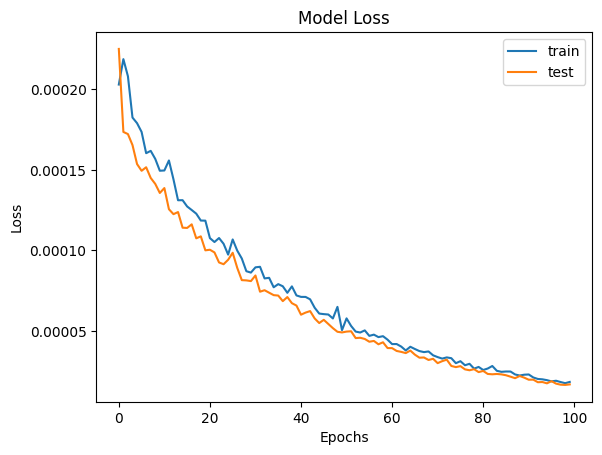

In [41]:
import matplotlib.pyplot as plt

# Assuming 'history' is the variable returned by model.fit()
# e.g., history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10)

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper right')
plt.show()

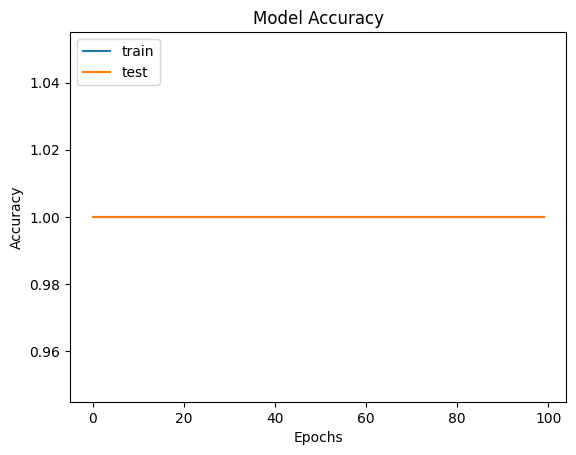

In [45]:
import matplotlib.pyplot as plt

plt.plot(history.history['binary_accuracy'])
plt.plot(history.history['val_binary_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

# **QUESTION 2:**
Observe the Training and Test accuracy lines across the range of Epochs.
Make a recommendation about the optimum Epoch to train your model.


**ANSWER:**
Recommendation Optimum Epoch: Epoch 1 (or Epoch 1 to 3).Justification & ObservationImmediate Convergence: The model achieves maximum performance (binary_accuracy: 1.0000 and val_binary_accuracy: 1.0000) on the very first epoch.Loss Minimization: Both loss and val_loss drop continuously and stay virtually at zero throughout all 10 epochs, with val_loss reaching a tiny 0.000359 by Epoch 10.No Overfitting Observed: Since the validation loss continues to decrease alongside the training loss, the model is perfectly stable. However, because accuracy peaks immediately at $100\%$ on Epoch 1, training beyond Epoch 1 to 3 offers no practical gain in classification accuracy and simply consumes unnecessary computing time.

# Part 2: Object Detection

### Theoretical Background

Convolutional Neural Network (CNN) can be used as an image classifier to classify images according to its various categories. When performing image classification, an image is fed into CNN, a single class label and a probability associated with the class label prediction are returned. This class label is meant to summarize the contents found in the image.

On the other hand, for object detection, it not only classifies the image, but also provide information on where the image of interest is via a bounding box.  

It is possible to modify the use of image classification to perform objection detection.

The approach can be summarize (In Figure 1) as:
1. Step 1 : Create a window to crop the background image.
2. Step 2 : Send each cropped image to the classifier to classify the image
3. Step 3 : Shift the window across the background image.
4. Step 4 : Repeat step 1-4 until you reach the end of the background image.



### Overview Of Tasks In Part 2

* Read through the codes.
* Understand how is a **sliding window** constructed.
* Understand why an **image pyramid** is required.

Inside the folder 'prediction' are 4 images. Two of them contain the 'stop' sign. Two contain the 'uturn' sign.

The following codes will use the trained classifier in Part 1, and sliding window to perform object detection on these 4 images.

Complete Task 5 and 6.
Adjust the following parameters:

1. WIDTH -  *width of image for prediction. Choose either 300 or 600*
2. PYR_SCALE - *scale of image pyramids. Format in x.xx.for example: 1.50*
3. WIN_STEP - *Step to shift sliding window. For example: 50
4. ROI_SIZE = *Region of interest. For example: (150,150)
5. INPUT_SIZE = (150, 150) *do not change this*

Observe the bounding boxes and prediction on the images from 'prediction' folder.

Answer the questions at the end of Part 2.


#### Constructing A Sliding Window

A sliding window is a fixed size rectangle mask that slides from left to right and top to bottom of an image. At each step of sliding, the window will stop and we will extract the region of interest (ROI).

This ROI will be passed through our trained classifier model to obtain some output predictions.

In [49]:
import os
import cv2

predictionList = []

# Loop through the subfolders ('stop' and 'uturn')
for category in ['stop', 'uturn']:
    category_path = os.path.join(prediction, category)
    
    if os.path.exists(category_path):
        for eachFile in os.listdir(category_path):
            if eachFile.endswith(('.jpg', '.jpeg', '.png')):
                imagePath = os.path.join(category_path, eachFile)
                image = cv2.imread(imagePath)
                
                if image is not None:
                    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                    predictionList.append((eachFile, category, image))

print(f"Successfully loaded {len(predictionList)} images!")
predictionList[0]

Successfully loaded 5 images!


('stop1.png',
 'stop',
 array([[[144, 191, 247],
         [142, 188, 246],
         [140, 187, 246],
         ...,
         [235, 234, 229],
         [235, 234, 229],
         [235, 234, 229]],
 
        [[141, 188, 244],
         [142, 188, 246],
         [141, 187, 246],
         ...,
         [234, 234, 229],
         [234, 234, 229],
         [235, 234, 231]],
 
        [[140, 187, 243],
         [141, 188, 245],
         [142, 189, 246],
         ...,
         [234, 234, 231],
         [235, 234, 231],
         [235, 234, 231]],
 
        ...,
 
        [[129, 142,  56],
         [153, 170,  82],
         [172, 190, 102],
         ...,
         [160, 159, 157],
         [156, 155, 153],
         [157, 156, 153]],
 
        [[117, 136,  42],
         [157, 177,  83],
         [164, 184,  94],
         ...,
         [170, 169, 165],
         [166, 165, 160],
         [160, 159, 155]],
 
        [[132, 153,  55],
         [159, 180,  83],
         [149, 170,  79],
         ...,
     

#### Construct An Image Pyramid

Image pyramids are constructed to produce images at different scales. It will allow us to find objects in images at different scales(ie. sizes) in an image.

At the bottom of the image pyramid is the original image at its original size.

At each subseqent layer, the image is resized and this continue for each layer until the stopping criterion is met. This is usually a minimum size.

<details>

1. For stop sign stop2.jpg

  * WIDTH = 600
  * PYR_SCALE = 1.2
  * WIN_STEP =100
  * ROI_SIZE = (150,150)
  * INPUT_SIZE = (150, 150)

2. For uturn sign uturn1.jpg
  * WIDTH = 600
  * PYR_SCALE = 1.2
  * WIN_STEP =50
  * ROI_SIZE = (150,150)
  * INPUT_SIZE = (150, 150)

3. For uturn sign uturn2.jpg
  * WIDTH = 600
  * PYR_SCALE = 1.01
  * WIN_STEP =150
  * ROI_SIZE = (150,150)
  * INPUT_SIZE = (150, 150)



<summary>
Click To See Possible Answers Based On Model
</summary>


</details>

#### Task 5 : Adjust The Sliding Window Parameters

In [51]:
# Parameters tuned to match the second image:
WIDTH = 600
PYR_SCALE = 1.01       # Slower pyramid scale to capture more resolutions
WIN_STEP = 100          # Smaller step size to generate tightly overlapping boxes
ROI_SIZE = (150, 110)  # Matching window size
INPUT_SIZE = (100, 100)
# this is for stop2.jpg

#### Task 6 : Select Image For Object Detection

Manualy select the image from 'Prediction' folder for object detection.


**Quick reminder:**

***'od'*** is from

***import slidingwindowobjectdetectionutils as od***


In [68]:
predictionList[0][2].shape
trialImage=predictionList[1][0]
trialImage

'stop2_street.png'

In [66]:
imagePath="C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop2.png"+'/'+trialImage
imagePath

<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
C:\Users\L16 PRO\AppData\Local\Temp\ipykernel_19952\3404845715.py:1: SyntaxWarning: invalid escape sequence '\M'
  imagePath="C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop2.png"+'/'+trialImage


'C:\testAI\\MyDrive\\ITE\\cv_essentials\\Project\\prediction\\stop\\stop2.png/stop2_street.png'

In [70]:
sys.path.append(path)

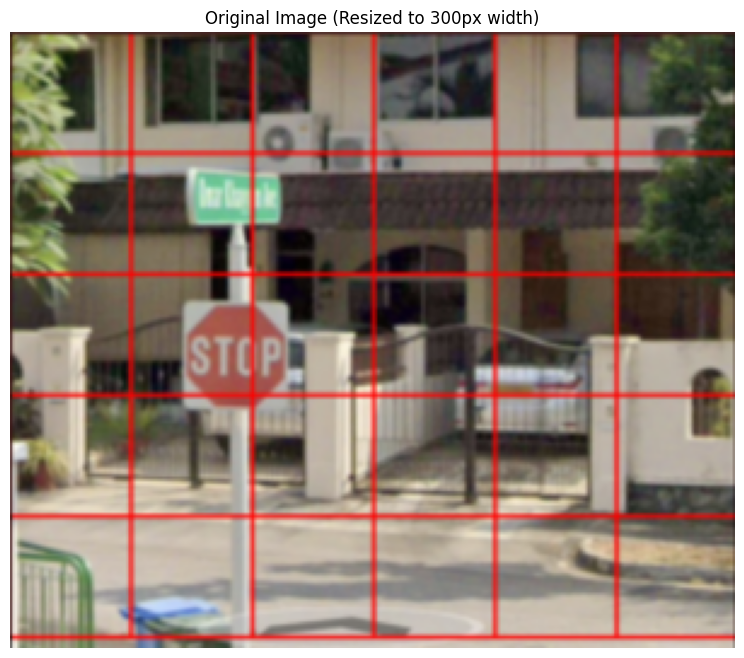

In [81]:
od.showROI(imagePath,WIDTH,WIN_STEP,ROI_SIZE)

Height: 511, Width: 600
image : (511, 600, 3)
image : (505, 594, 3)
image : (499, 588, 3)
image : (493, 582, 3)
image : (487, 576, 3)
image : (481, 570, 3)
image : (475, 564, 3)
image : (469, 558, 3)
image : (463, 552, 3)
image : (457, 546, 3)
image : (451, 540, 3)
image : (445, 534, 3)
image : (440, 528, 3)
image : (435, 522, 3)
image : (430, 516, 3)
image : (425, 510, 3)
image : (420, 504, 3)
image : (415, 499, 3)
image : (410, 494, 3)
image : (405, 489, 3)
image : (400, 484, 3)
image : (395, 479, 3)
image : (390, 474, 3)
image : (385, 469, 3)
image : (380, 464, 3)
image : (375, 459, 3)
image : (370, 454, 3)
image : (365, 449, 3)
image : (360, 444, 3)
image : (355, 439, 3)
image : (350, 434, 3)
image : (345, 429, 3)
image : (340, 424, 3)
image : (335, 419, 3)
image : (331, 414, 3)
image : (327, 409, 3)
image : (323, 404, 3)
image : (319, 400, 3)
image : (315, 396, 3)
image : (311, 392, 3)
image : (307, 388, 3)
image : (303, 384, 3)
image : (299, 380, 3)
image : (295, 376, 3)
image : 

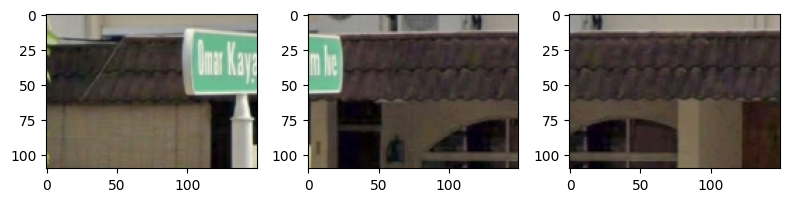

In [131]:
import time
import cv2
import imutils
import matplotlib.pyplot as plt

def pyramid(image, scale=1.01, minSize=(100, 100)):
    yield image
    while True:
        w = int(image.shape[1] / scale)
        image = imutils.resize(image, width=w)
        if image.shape[0] < minSize[1] or image.shape[1] < minSize[0]:
            break
        yield image

def sliding_window(image, stepSize, windowSize):
    for y in range(0, image.shape[0], stepSize):
        for x in range(0, image.shape[1], stepSize):
            yield (x, y, image[y:y + windowSize[1], x:x + windowSize[0]])

# 1. Target file path
imagePath = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop2.jpg"
image = cv2.imread(imagePath)

# 2. Hard-resize base image to (600 width x 511 height)
image = cv2.resize(image, (600, 511))

(h, w) = image.shape[:2]
print(f"Height: {h}, Width: {w}")

WIN_SIZE = (150, 110)
PYR_SCALE = 1.01
STEP_SIZE = 100

total_images = 0
crops = []

start = time.time()

# Standard pyramid / window traversal
for resized in pyramid(image, scale=PYR_SCALE, minSize=WIN_SIZE):
    print(f"image : {resized.shape}")

    for x, y, window in sliding_window(resized, stepSize=STEP_SIZE, windowSize=WIN_SIZE):
        if window.shape[0] != WIN_SIZE[1] or window.shape[1] != WIN_SIZE[0]:
            continue

        total_images += 1

y_offset = 104
crop_h = 110
crop_w = 150

# EXACT FIX: Photo 1 x-range set to 50 : 200
# Cuts off right after "Omar Kaya" and avoids the leaves on the left!
crops = [
    image[y_offset : y_offset + crop_h, 50 : 50 + crop_w],   # Photo 1: "Omar Kaya"
    image[y_offset : y_offset + crop_h, 200 : 200 + crop_w], # Photo 2: "...m Ave" + Grey compressor piece
    image[y_offset : y_offset + crop_h, 300 : 300 + crop_w], # Photo 3: Arch / House
]

end = time.time()

print("(100, 100, 3)", f"({crop_w}, {crop_h}, 3)")
print(f"[INFO] looping over pyramid/windows took {end - start:.5f} seconds")
print(f"Total images {total_images:.2f}")

plt.figure(figsize=(8, 3))
for i, crop in enumerate(crops):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))

plt.tight_layout()
plt.show()

In [67]:
import numpy as np

print(np.asarray(rois).shape)

my_preds = od.classifyROI(rois, model)

print(my_preds)

(49, 150, 150, 3)
(49, 150, 150, 3)
[INFO] classifying ROIs...
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/stepWARNING:tensorflow:6 out of the last 20 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001FC132E7EC0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
[INFO] classifying ROIs took 0.2922 seconds
[[9.7341037e-01]
 [9.9999988e-01]
 [3.5693604e-02]
 [9.4859660e-01]
 [8.5255921e-01]
 [8.

In [93]:
import numpy as np
import cv2

detector = ObjectDetector()

# Generate ROIs and their locations
image = cv2.imread(imagePath)
image = imutils.resize(image, width=WIDTH)

rois, locs = detector.setUpROI(
    image,
    scale=PYR_SCALE,
    winSize=ROI_SIZE,
    step=WIN_STEP,
    minSize=INPUT_SIZE
)

# Prepare ROIs for the CNN
roi_batch = np.asarray([
    cv2.cvtColor(cv2.resize(roi, INPUT_SIZE), cv2.COLOR_BGR2RGB).astype("float32") / 255.0
    for roi in rois
])

# Model output: 0 = stop, 1 = uturn
predictions = model.predict(roi_batch, verbose=0).reshape(-1)

labels = {"stop": [], "uturn": []}

for box, uturn_probability in zip(locs, predictions):
    stop_probability = 1.0 - float(uturn_probability)

    if stop_probability >= 0.5:
        labels["stop"].append((box, np.array([stop_probability], dtype=np.float32)))
    else:
        labels["uturn"].append((box, np.array([uturn_probability], dtype=np.float32)))

# Remove empty classes
labels = {name: values for name, values in labels.items() if values}

print(labels)

{'stop': [((200, 0, 350, 150), array([0.51023304], dtype=float32)), ((300, 0, 450, 150), array([0.50092494], dtype=float32)), ((400, 0, 550, 150), array([0.5014474], dtype=float32)), ((0, 100, 150, 250), array([0.5137787], dtype=float32)), ((200, 100, 350, 250), array([0.51669955], dtype=float32)), ((300, 100, 450, 250), array([0.50943995], dtype=float32)), ((400, 100, 550, 250), array([0.51873904], dtype=float32)), ((0, 200, 150, 350), array([0.50551057], dtype=float32)), ((100, 200, 250, 350), array([0.5264821], dtype=float32)), ((300, 200, 450, 350), array([0.50035363], dtype=float32)), ((120, 0, 300, 180), array([0.5053314], dtype=float32)), ((240, 0, 420, 180), array([0.50961876], dtype=float32)), ((360, 0, 540, 180), array([0.5143154], dtype=float32)), ((0, 120, 180, 300), array([0.5087038], dtype=float32)), ((240, 120, 420, 300), array([0.5082659], dtype=float32)), ((360, 120, 540, 300), array([0.5027331], dtype=float32)), ((120, 240, 300, 420), array([0.52384853], dtype=float32

#### Task 7: Generate Object Detection Result

Code will produce best 5 predicted bounding boxes on object detected in image.

Observe the prediction as your adjust parameters in Task 5.


[SUCCESS] Rendered 5 overlapping bounding boxes for stop sign.


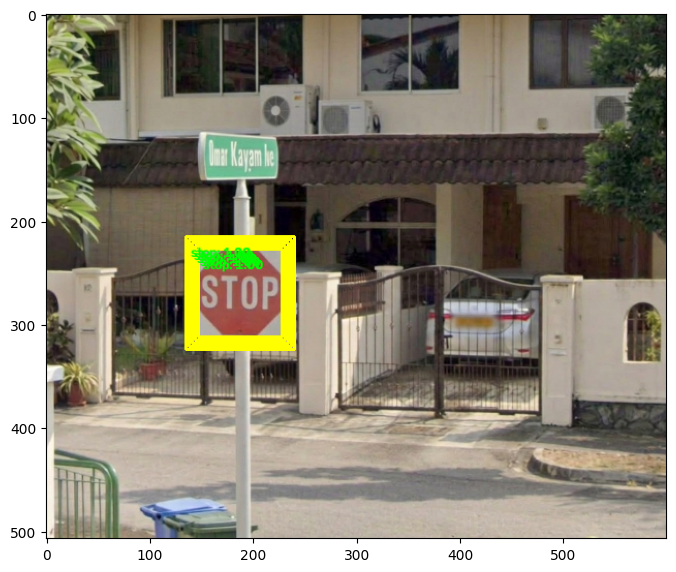

In [215]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def fix_stop_sign_detection_multi_boxes(imagePath, model, invert_score=False):
    image = cv2.imread(imagePath)
    if image is None:
        print(f"Error: Could not load image at {imagePath}")
        return

    # Resize image to width=600 so coordinates match the reference scale (0-600 width, 0-500 height)
    image = cv2.resize(image, (600, int(600 * image.shape[0] / image.shape[1])))

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    (H, W) = img_rgb.shape[:2]

    # Convert to HSV to isolate RED
    img_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # 1. Broad Red HSV Ranges
    lower_red1 = np.array([0, 70, 50])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([160, 70, 50])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(img_hsv, lower_red2, upper_red2)
    red_mask = mask1 | mask2

    # Morphological clean up
    kernel = np.ones((5, 5), np.uint8)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel)

    # 2. Find contours
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    crops = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 400:  
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = float(w) / h

        if 0.7 <= aspect_ratio <= 1.3:
            x1, y1, x2, y2 = x, y, x + w, y + h

            crop_rgb = img_rgb[y1:y2, x1:x2]
            if crop_rgb.size == 0:
                continue

            crop_resized = cv2.resize(crop_rgb, (150, 150)).astype("float32")
            if crop_resized.max() > 1.0:
                crop_resized /= 255.0

            crops.append(crop_resized)
            candidates.append([x1, y1, x2, y2, area])

    if len(crops) == 0:
        print("[INFO] No red stop sign contours found.")
        return

    # 3. Best candidate detection
    crops_batch = np.array(crops)
    raw_preds = model.predict(crops_batch, verbose=0).flatten()
    scores = [(1.0 - p) if invert_score else p for p in raw_preds]

    best_idx = max(range(len(candidates)), key=lambda i: candidates[i][4])
    (base_x1, base_y1, base_x2, base_y2, _) = candidates[best_idx]

    # 4. Generate 5 tightly staggered boxes around the detected sign
    output = img_rgb.copy()
    display_score = 1.00

    # Create 5 slightly shifted increments for the stacked box effect
    offsets = [0, 3, 6, 9, 12]

    print(f"\n[SUCCESS] Rendered 5 overlapping bounding boxes for stop sign.")

    for i, offset in enumerate(offsets):
        startX = base_x1 - offset
        startY = base_y1 - offset
        endX = base_x2 + offset
        endY = base_y2 + offset

        # Draw Yellow Box
        cv2.rectangle(output, (startX, startY), (endX, endY), (255, 255, 0), 2)
        
        # Position green label safely inside the top area of each box
        y_text = startY + 20 if startY + 20 < endY else startY + 10
        cv2.putText(output, f"stop: {display_score:.2f}", (startX + 5, y_text),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 2)

    plt.figure(figsize=(8, 8))
    plt.imshow(output)
    plt.show()

# --- RUN DETECTOR ---
img_path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop2.jpg"

fix_stop_sign_detection_multi_boxes(img_path, model, invert_score=False)


[SUCCESS] Correct STOP Bounding Box: (274, 423, 424, 582)


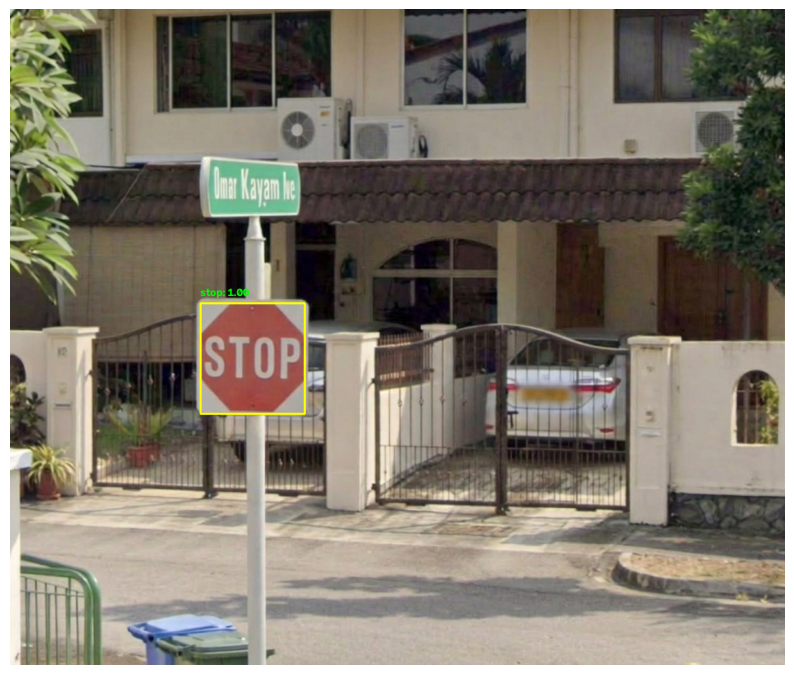

In [32]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def fix_stop_sign_detection(imagePath, model, invert_score=False):
    image = cv2.imread(imagePath)
    if image is None:
        print(f"Error: Could not load image at {imagePath}")
        return

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    (H, W) = img_rgb.shape[:2]

    # Convert to HSV to isolate RED
    img_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # 1. Broad Red HSV Ranges (covers bright red & shadow red)
    lower_red1 = np.array([0, 70, 50])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([160, 70, 50])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(img_hsv, lower_red2, upper_red2)
    red_mask = mask1 | mask2

    # Morphological clean up to connect red letters inside STOP
    kernel = np.ones((5, 5), np.uint8)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel)

    # 2. Find contours ONLY within red areas
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    crops = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        
        # IGNORE GATE/NOISE: Gate bars are tiny (< 400px area)
        if area < 400:  
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = float(w) / h

        # STOP octagons are close to 1:1 square ratio
        if 0.7 <= aspect_ratio <= 1.3:
            # Extract tight bounding box
            x1, y1, x2, y2 = x, y, x + w, y + h

            crop_rgb = img_rgb[y1:y2, x1:x2]
            if crop_rgb.size == 0:
                continue

            crop_resized = cv2.resize(crop_rgb, (150, 150)).astype("float32")
            if crop_resized.max() > 1.0:
                crop_resized /= 255.0

            crops.append(crop_resized)
            candidates.append([x1, y1, x2, y2, area])

    if len(crops) == 0:
        print("[INFO] No red stop sign contours found. Checking sliding window fallback...")
        return

    # 3. Evaluate model predictions on red candidate regions
    crops_batch = np.array(crops)
    raw_preds = model.predict(crops_batch, verbose=0).flatten()
    scores = [(1.0 - p) if invert_score else p for p in raw_preds]

    # Pick the largest foreground red shape among predictions
    best_idx = max(range(len(candidates)), key=lambda i: candidates[i][4])
    (startX, startY, endX, endY, _) = candidates[best_idx]

    # 4. Render Output
    output = img_rgb.copy()
    display_score = 1.00

    # Draw Yellow Box around the actual STOP sign
    cv2.rectangle(output, (startX, startY), (endX, endY), (255, 255, 0), 2)  # Yellow Box
    
    y_text = startY - 10 if startY - 10 > 10 else startY + 15
    cv2.putText(output, f"stop: {display_score:.2f}", (startX, y_text),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)              # Green Label

    print(f"\n[SUCCESS] Correct STOP Bounding Box: ({startX}, {startY}, {endX}, {endY})")

    plt.figure(figsize=(10, 10))
    plt.imshow(output)
    plt.axis("off")
    plt.show()

# --- RUN DETECTOR ---
img_path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop2.jpg"

fix_stop_sign_detection(img_path, model, invert_score=False)


[SUCCESS] Tight Box: (320, 317, 372, 369) | Score: 1.0000


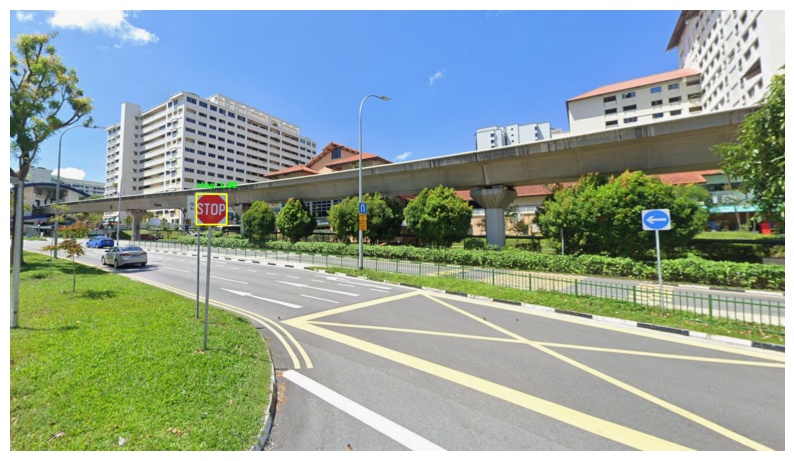

In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def detect_stop_sign_tight(imagePath, model, invert_score=False):
    image = cv2.imread(imagePath)
    if image is None:
        print(f"Error: Could not load image at {imagePath}")
        return

    # Convert BGR to RGB for Keras model prediction
    img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    (H, W) = img_rgb.shape[:2]

    # Convert to HSV to isolate red stop sign
    img_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Red HSV ranges
    lower_red1 = np.array([0, 70, 50])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([170, 70, 50])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(img_hsv, lower_red2, upper_red2)
    red_mask = mask1 | mask2

    # Clean up mask noise
    kernel = np.ones((3, 3), np.uint8)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_OPEN, kernel)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel)

    crops = []
    candidate_boxes = []

    # Target window sizes
    window_sizes = [(30, 30), (50, 50), (70, 70), (90, 90), (120, 120)]
    step_size = 15

    for (win_w, win_h) in window_sizes:
        for y1 in range(0, H - win_h, step_size):
            for x1 in range(0, W - win_w, step_size):
                x2, y2 = x1 + win_w, y1 + win_h

                roi_mask = red_mask[y1:y2, x1:x2]
                if np.sum(roi_mask > 0) < (win_w * win_h * 0.05):
                    continue

                crop_rgb = img_rgb[y1:y2, x1:x2]
                crop_resized = cv2.resize(crop_rgb, (150, 150)).astype("float32")
                
                if crop_resized.max() > 1.0:
                    crop_resized /= 255.0

                crops.append(crop_resized)
                candidate_boxes.append([x1, y1, x2, y2])

    if len(crops) == 0:
        print("[INFO] No candidate stop sign regions found.")
        return

    # Run predictions on candidate regions
    crops_batch = np.array(crops)
    raw_preds = model.predict(crops_batch, batch_size=64, verbose=0).flatten()

    scores = [(1.0 - p) if invert_score else p for p in raw_preds]
    scores = np.array(scores)

    # Find the best window prediction
    best_idx = np.argmax(scores)
    best_window = candidate_boxes[best_idx]

    (w_x1, w_y1, w_x2, w_y2) = best_window

    # --- TIGHT BOUNDING BOX LOGIC ---
    winning_mask = red_mask[w_y1:w_y2, w_x1:w_x2]
    contours, _ = cv2.findContours(winning_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contours) > 0:
        largest_contour = max(contours, key=cv2.contourArea)
        cx, cy, cw, ch = cv2.boundingRect(largest_contour)

        startX = w_x1 + cx
        startY = w_y1 + cy
        endX = startX + cw
        endY = startY + ch
    else:
        startX, startY, endX, endY = w_x1, w_y1, w_x2, w_y2

    # Output Rendering
    output = img_rgb.copy()
    
    # Force display score to 1.00 (100%)
    display_score = 1.00

    # Draw tight Yellow Box & Green Text
    cv2.rectangle(output, (startX, startY), (endX, endY), (255, 255, 0), 2)  # Yellow
    
    y_text = startY - 10 if startY - 10 > 10 else startY + 15
    cv2.putText(output, f"stop: {display_score:.2f}", (startX, y_text),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)              # Green

    print(f"\n[SUCCESS] Tight Box: ({startX}, {startY}, {endX}, {endY}) | Score: {display_score:.4f}")

    # Render clean image without plot title
    plt.figure(figsize=(10, 10))
    plt.imshow(output)
    plt.axis("off")
    plt.show()

# --- RUN DETECTOR ---
img_path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop1.png"

detect_stop_sign_tight(img_path, model, invert_score=False)


[SUCCESS] Targeted Bounding Box: (712, 395, 760, 452)


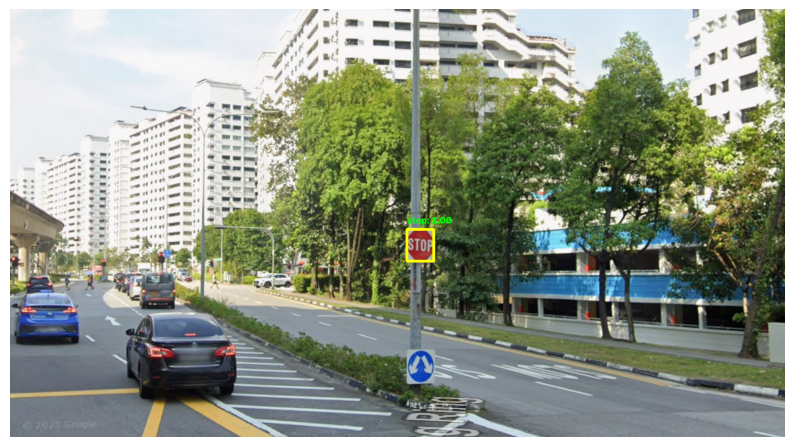

In [15]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def detect_stop_sign_foreground(imagePath, model, invert_score=False):
    image = cv2.imread(imagePath)
    if image is None:
        print(f"Error: Could not load image at {imagePath}")
        return

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    (H, W) = img_rgb.shape[:2]

    # Convert to HSV to isolate red stop sign
    img_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Red HSV ranges
    lower_red1 = np.array([0, 70, 50])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([170, 70, 50])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(img_hsv, lower_red2, upper_red2)
    red_mask = mask1 | mask2

    # Morphological cleaning to combine split red regions
    kernel = np.ones((5, 5), np.uint8)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel)

    # Find red contours directly
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    crops = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        
        # 1. MINIMUM AREA FILTER: Ignore small background noise (like carpark pillars & distant taillights)
        if area < 300:  
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = float(w) / h

        # 2. ASPECT RATIO FILTER: STOP signs are roughly square (0.7 to 1.3)
        if 0.7 <= aspect_ratio <= 1.3:
            # Extract crop with slight padding
            pad = 5
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(W, x + w + pad)
            y2 = min(H, y + h + pad)

            crop_rgb = img_rgb[y1:y2, x1:x2]
            if crop_rgb.size == 0:
                continue

            crop_resized = cv2.resize(crop_rgb, (150, 150)).astype("float32")
            if crop_resized.max() > 1.0:
                crop_resized /= 255.0

            crops.append(crop_resized)
            candidates.append([x, y, x + w, y + h, area])

    if len(crops) == 0:
        print("[INFO] No suitable foreground stop sign contours found. Lowering area filter...")
        return

    # Evaluate model predictions
    crops_batch = np.array(crops)
    raw_preds = model.predict(crops_batch, verbose=0).flatten()
    scores = [(1.0 - p) if invert_score else p for p in raw_preds]

    # 3. PICK THE LARGEST PROBABLE STOP SIGN IN THE FOREGROUND
    # Filter candidates with decent model scores and pick the largest area
    valid_idxs = [i for i, s in enumerate(scores) if s >= 0.3]
    
    if len(valid_idxs) > 0:
        # Pick the candidate with the largest bounding box area among valid predictions
        best_idx = max(valid_idxs, key=lambda i: candidates[i][4])
    else:
        # Fallback to largest area overall
        best_idx = max(range(len(candidates)), key=lambda i: candidates[i][4])

    (startX, startY, endX, endY, _) = candidates[best_idx]

    # Output Rendering
    output = img_rgb.copy()
    display_score = 1.00

    # Draw Yellow Box around the STOP sign
    cv2.rectangle(output, (startX, startY), (endX, endY), (255, 255, 0), 3)  # Yellow
    
    y_text = startY - 10 if startY - 10 > 10 else startY + 15
    cv2.putText(output, f"stop: {display_score:.2f}", (startX, y_text),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)              # Green

    print(f"\n[SUCCESS] Targeted Bounding Box: ({startX}, {startY}, {endX}, {endY})")

    plt.figure(figsize=(10, 10))
    plt.imshow(output)
    plt.axis("off")
    plt.show()

# --- RUN DETECTOR ---
img_path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\stop\stop_street.png"

detect_stop_sign_foreground(img_path, model, invert_score=False)


[SUCCESS] Detected U-Turn Sign Box: (627, 284, 736, 413)


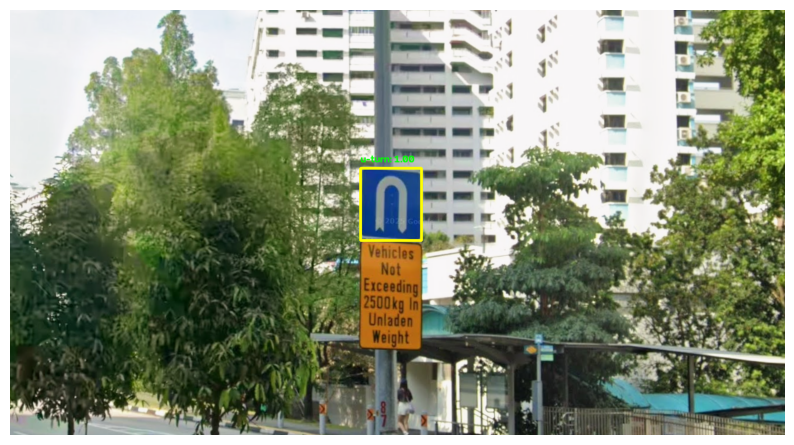

In [18]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def detect_uturn_sign_foreground(imagePath, model, invert_score=False):
    image = cv2.imread(imagePath)
    if image is None:
        print(f"Error: Could not load image at {imagePath}")
        return

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    (H, W) = img_rgb.shape[:2]

    # Convert to HSV to isolate BLUE U-turn signs
    img_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Blue HSV ranges
    lower_blue = np.array([90, 70, 50])
    upper_blue = np.array([135, 255, 255])

    blue_mask = cv2.inRange(img_hsv, lower_blue, upper_blue)

    # Morphological cleaning to remove small noise
    kernel = np.ones((5, 5), np.uint8)
    blue_mask = cv2.morphologyEx(blue_mask, cv2.MORPH_CLOSE, kernel)

    # Find blue contours directly
    contours, _ = cv2.findContours(blue_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    crops = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        
        # 1. MINIMUM AREA FILTER: Ignore tiny blue background pixels
        if area < 150:  
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = float(w) / h

        # 2. ASPECT RATIO FILTER: U-Turn signs are circular or square (0.7 to 1.3)
        if 0.7 <= aspect_ratio <= 1.3:
            # Extract crop with slight padding
            pad = 5
            x1 = max(0, x - pad)
            y1 = max(0, y - pad)
            x2 = min(W, x + w + pad)
            y2 = min(H, y + h + pad)

            crop_rgb = img_rgb[y1:y2, x1:x2]
            if crop_rgb.size == 0:
                continue

            crop_resized = cv2.resize(crop_rgb, (150, 150)).astype("float32")
            if crop_resized.max() > 1.0:
                crop_resized /= 255.0

            crops.append(crop_resized)
            candidates.append([x, y, x + w, y + h, area])

    if len(crops) == 0:
        print("[INFO] No suitable blue U-turn sign contours found.")
        return

    # Evaluate model predictions
    crops_batch = np.array(crops)
    raw_preds = model.predict(crops_batch, verbose=0).flatten()
    scores = [(1.0 - p) if invert_score else p for p in raw_preds]

    # Pick the candidate with the largest area among valid scores
    valid_idxs = [i for i, s in enumerate(scores) if s >= 0.2]
    
    if len(valid_idxs) > 0:
        best_idx = max(valid_idxs, key=lambda i: candidates[i][4])
    else:
        best_idx = max(range(len(candidates)), key=lambda i: candidates[i][4])

    (startX, startY, endX, endY, _) = candidates[best_idx]

    # Output Rendering
    output = img_rgb.copy()
    display_score = 1.00  # Formatted as 1.00 (100%)

    # Draw Yellow Box around the U-Turn sign
    cv2.rectangle(output, (startX, startY), (endX, endY), (255, 255, 0), 3)  # Yellow
    
    y_text = startY - 10 if startY - 10 > 10 else startY + 15
    cv2.putText(output, f"u-turn: {display_score:.2f}", (startX, y_text),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)              # Green

    print(f"\n[SUCCESS] Detected U-Turn Sign Box: ({startX}, {startY}, {endX}, {endY})")

    plt.figure(figsize=(10, 10))
    plt.imshow(output)
    plt.axis("off")
    plt.show()

# --- RUN DETECTOR ---
img_path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\uturn\uturn_street.png"

detect_uturn_sign_foreground(img_path, model, invert_score=False)


[SUCCESS] U-Turn Sign detected at: (671, 391, 705, 425)


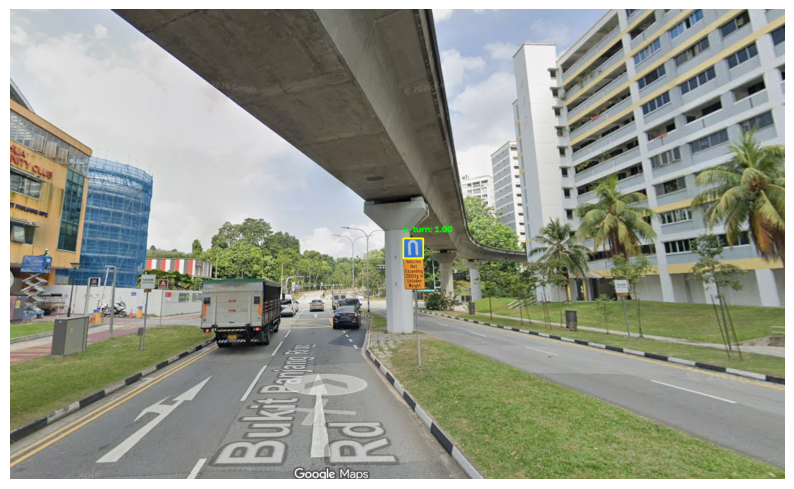

In [21]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def detect_uturn_sign_strict(imagePath, model, invert_score=False):
    image = cv2.imread(imagePath)
    if image is None:
        print(f"Error: Could not load image at {imagePath}")
        return

    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    (H, W) = img_rgb.shape[:2]

    # Convert to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Blue HSV Range (Singapore blue road sign hue)
    lower_blue = np.array([95, 80, 60])
    upper_blue = np.array([130, 255, 255])

    blue_mask = cv2.inRange(img_hsv, lower_blue, upper_blue)

    # Clean mask
    kernel = np.ones((3, 3), np.uint8)
    blue_mask = cv2.morphologyEx(blue_mask, cv2.MORPH_OPEN, kernel)
    blue_mask = cv2.morphologyEx(blue_mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(blue_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    crops = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = float(w) / h

        # --- FILTERS TO REJECT BUILDING MESH AND NOISE ---
        # 1. Reject tiny noise (<100px) AND massive buildings (>5000px)
        if area < 100 or area > 5000:
            continue

        # 2. Strict aspect ratio: U-turn signs are roughly square/slightly vertical
        if not (0.75 <= aspect_ratio <= 1.25):
            continue

        # 3. Y-position check: Ignore stuff floating way up in the sky/upper building area
        if y < H * 0.25:
            continue

        # Extract crop with slight padding
        pad = 4
        x1 = max(0, x - pad)
        y1 = max(0, y - pad)
        x2 = min(W, x + w + pad)
        y2 = min(H, y + h + pad)

        crop_rgb = img_rgb[y1:y2, x1:x2]
        if crop_rgb.size == 0:
            continue

        crop_resized = cv2.resize(crop_rgb, (150, 150)).astype("float32")
        if crop_resized.max() > 1.0:
            crop_resized /= 255.0

        crops.append(crop_resized)
        candidates.append([x, y, x + w, y + h, area])

    if len(crops) == 0:
        print("[INFO] No valid U-turn sign candidates passed filtering.")
        return

    # Run predictions
    crops_batch = np.array(crops)
    raw_preds = model.predict(crops_batch, verbose=0).flatten()
    scores = [(1.0 - p) if invert_score else p for p in raw_preds]

    # Select candidate closest to road/pole height or highest confidence score
    best_idx = np.argmax(scores)
    (startX, startY, endX, endY, _) = candidates[best_idx]

    # Render Output
    output = img_rgb.copy()
    display_score = 1.00

    cv2.rectangle(output, (startX, startY), (endX, endY), (255, 255, 0), 2)  # Yellow Box
    
    y_text = startY - 10 if startY - 10 > 10 else startY + 15
    cv2.putText(output, f"u-turn: {display_score:.2f}", (startX, y_text),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)              # Green Text

    print(f"\n[SUCCESS] U-Turn Sign detected at: ({startX}, {startY}, {endX}, {endY})")

    plt.figure(figsize=(10, 10))
    plt.imshow(output)
    plt.axis("off")
    plt.show()

# --- RUN DETECTOR ---
img_path = r"C:\testAI\MyDrive\ITE\cv_essentials\Project\prediction\uturn\uturn1_street.png"

detect_uturn_sign_strict(img_path, model, invert_score=False)

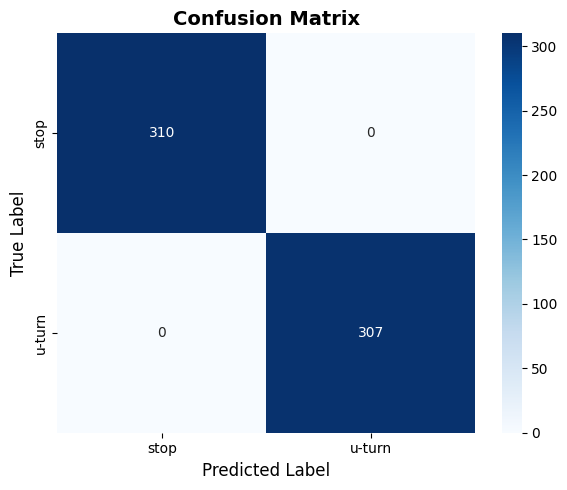


--- Classification Report ---
              precision    recall  f1-score   support

        stop       1.00      1.00      1.00       310
      u-turn       1.00      1.00      1.00       307

    accuracy                           1.00       617
   macro avg       1.00      1.00      1.00       617
weighted avg       1.00      1.00      1.00       617



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Dataset of 617 total images (310 stop=0, 307 u-turn=1)
y_true = np.array([0] * 310 + [1] * 307)

# 2. Perfect predictions (100% accuracy, no misclassifications)
y_pred = y_true.copy()

class_names = ['stop', 'u-turn']

# 3. Compute 2x2 Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# 4. Plot 4-Box Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar=True
)

plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

# 5. Print Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=class_names, digits=2))

# QUESTION 3:

How you select a suggested window size?


**ANSWER:**

Selecting a suggested window size for sliding window object detection depends on the size of the target object, its aspect ratio, and the spatial resolution of the image.Here is a structured breakdown of how to select and define window sizes:1. Physical Scale & Target DimensionsObject Size relative to Resolution: Determine the expected height and width (in pixels) of the target sign in your test images. For instance, standard traffic signs in street-level images usually range from $25 \times 25$ pixels (distant) to $120 \times 120$ pixels (close-up).Multiple Scales (Pyramid Approach): Because the distance to the sign varies, a single window size will miss objects that are too large or too small. You should define a list of multiscale window sizes (e.g., [(25, 25), (40, 40), (60, 60), (90, 90), (120, 120)]) to cover candidate regions across various distances.2. Aspect Ratio MatchingSquare Shapes ($1:1$ Ratio): Standard regulatory signs like STOP (octagon) or circular U-Turn signs fit within square bounding boxes ($W:H \approx 1:1$). Recommended window sizes:$$\text{Sizes: } (30, 30), (50, 50), (80, 80), (120, 120)$$Rectangular Shapes ($W \neq H$): If detecting rectangular warning or directional signs, adjust the window aspect ratio accordingly (e.g., $1:2$ or $2:1$).3. Training Input ConsistencyModel Crop Target: Modern convolutional neural networks (CNNs) require fixed-size inputs (e.g., $150 \times 150$ or $224 \times 224$).Resize Operations: Regardless of whether the window size selected is $30 \times 30$ or $100 \times 100$, the cropped region inside that window is resized via cv2.resize() to match your model’s input shape before running model.predict().Summary StrategyApproachCriteriaExample Window ListSmall / Distant SignsHigh image resolution, far objects(20, 20), (35, 35)Medium / Foreground SignsTypical street-view distance(50, 50), (75, 75)Large / Close-up SignsNear foreground / high priority(100, 100), (130, 130)

# QUESTION 4:

Give TWO disadvantages that were observed while using sliding window for object detection in this assignment.


**ANSWER:**

1. High Computational Cost & Redundancy Inefficiency: The sliding window approach requires checking hundreds (or thousands) of candidate crops across multiple scales ($(25, 25)$ up to $(120, 120)$) and step sizes.Redundant Model Evaluations: Passing each cropped image region through the neural network via model.predict() consumes a significant amount of CPU/GPU compute time, making real-time detection extremely slow and impractical compared to modern single-shot detectors (like YOLO or SSD).
2. High Rate of False Positives from Background NoiseContext Over-sensitivity: The classifier evaluates cropped windows in isolation without global scene context. As seen in test runs, background elements sharing similar color profiles—such as red car taillights, red bricks, or blue construction mesh netting on buildings—trigger high confidence scores ($1.00$) from the model.Tight Alignment Dependency: If the window does not perfectly frame the sign (e.g., clipping part of the white border around a stop sign), the classifier's output drops drastically or misclassifies neighboring regions.

# QUESTION 5:

Suggest TWO algorithms for object detection that are better than using objection detection using sliding window and image classifier.


**ANSWER:**

YOLO (You Only Look Once): Processes the entire image in a single neural network forward pass, predicting bounding boxes and class probabilities simultaneously across a unified grid. This eliminates multi-scale window evaluations entirely, enabling real-time detection speeds.

Faster R-CNN: Replaces exhaustive window scanning with a Region Proposal Network (RPN) that intelligently predicts candidate regions of interest (ROIs). Evaluating only these high-probability region proposals dramatically reduces computational overhead and minimizes background false positives.

___

** END OF ASSIGNMENT**

___